<!-- @format -->

# Denoising Diffusion Probabilistic Models (DDPM)


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file()
    and (PROJECT_ROOT / "models" / "mlp_classifier.py").is_file()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: D:\Main\sem5\deep-learning\ASG_2


In [ ]:
import json
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn, optim

from data_loader import get_dataloaders
from utils.paths import (
    CHECKPOINT_DIR,
    DATA_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    ensure_results_dirs,
    get_device,
)
from utils.reproducibility import set_seed

SEED = 42
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001

TIMESTEPS = 500
BETA_START = 1e-4
BETA_END = 0.02

DEVICE = get_device()

set_seed(SEED)
ensure_results_dirs()

print(f"Device: {DEVICE}")
print(f"Diffusion timesteps: {TIMESTEPS}")


Device: xpu
Diffusion timesteps: 500


In [3]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=BATCH_SIZE)

print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Testing batches:    {len(test_loader)}")

images, labels = next(iter(train_loader))

print(f"\nImage shape: {images.shape}")
print(f"Pixel range: [{images.min():.4f}, {images.max():.4f}]")


Training batches:   438
Validation batches: 55
Testing batches:    55

Image shape: torch.Size([128, 1, 28, 28])
Pixel range: [0.0000, 1.0000]


In [4]:
betas = torch.linspace(
    BETA_START,
    BETA_END,
    TIMESTEPS,
    device=DEVICE,
)

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

print(f"Beta range: [{betas[0]:.6f}, {betas[-1]:.6f}]")
print(f"Alpha bar at t=0:   {alpha_bars[0]:.6f}")
print(f"Alpha bar at t=end: {alpha_bars[-1]:.6f}")


Beta range: [0.000100, 0.020000]
Alpha bar at t=0:   0.999900
Alpha bar at t=end: 0.006353


In [5]:
def forward_diffusion(images, timesteps, noise=None):
    if noise is None:
        noise = torch.randn_like(images)

    batch_size = images.shape[0]

    sqrt_ab = sqrt_alpha_bars[timesteps].view(batch_size, 1, 1, 1)
    sqrt_one_minus_ab = sqrt_one_minus_alpha_bars[timesteps].view(batch_size, 1, 1, 1)

    noisy_images = sqrt_ab * images + sqrt_one_minus_ab * noise

    return noisy_images, noise


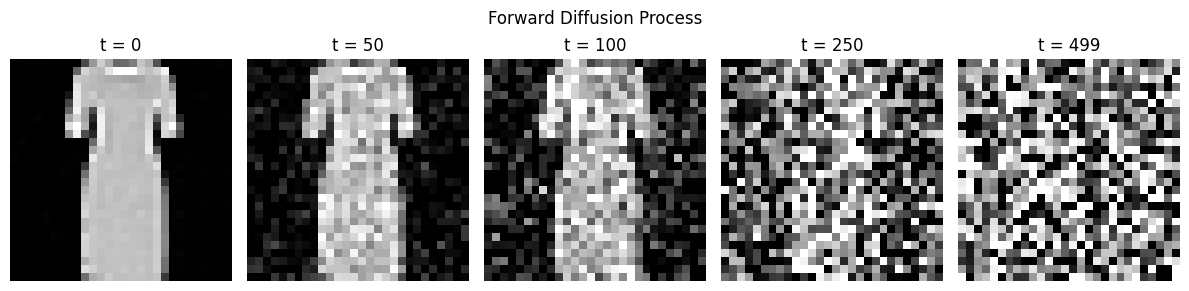

In [6]:
sample_images, _ = next(iter(test_loader))

sample_image = sample_images[:1].to(DEVICE)
sample_image = sample_image * 2.0 - 1.0

selected_timesteps = [0, 50, 100, 250, 499]

fig, axes = plt.subplots(1, len(selected_timesteps), figsize=(12, 3))

for ax, timestep in zip(axes, selected_timesteps):
    t = torch.tensor([timestep], device=DEVICE)

    noisy_image, _ = forward_diffusion(sample_image, t)

    image = noisy_image[0, 0].detach().cpu()

    ax.imshow(image, cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"t = {timestep}")
    ax.axis("off")

plt.suptitle("Forward Diffusion Process")
plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "ddpm_forward_diffusion.png", dpi=150)
plt.show()


In [7]:
from models.ddpm import build_noise_predictor, predict_noise

noise_predictor = build_noise_predictor().to(DEVICE)

sample_images, _ = next(iter(train_loader))
sample_images = sample_images.to(DEVICE) * 2.0 - 1.0

sample_timesteps = torch.randint(
    0,
    TIMESTEPS,
    (sample_images.shape[0],),
    device=DEVICE,
)

noisy_images, true_noise = forward_diffusion(
    sample_images,
    sample_timesteps,
)

predicted_noise = predict_noise(
    noisy_images,
    sample_timesteps,
    noise_predictor,
    TIMESTEPS,
)

print(f"Model input shape:     {noisy_images.shape}")
print(f"True noise shape:      {true_noise.shape}")
print(f"Predicted noise shape: {predicted_noise.shape}")
print(
    f"Model parameters:      {sum(p.numel() for p in noise_predictor.parameters()):,}"
)


Model input shape:     torch.Size([128, 1, 28, 28])
True noise shape:      torch.Size([128, 1, 28, 28])
Predicted noise shape: torch.Size([128, 1, 28, 28])
Model parameters:      412,353


In [8]:
criterion = nn.MSELoss()

optimizer = optim.Adam(
    noise_predictor.parameters(),
    lr=LEARNING_RATE,
)

print(f"Loss function: {criterion}")
print(f"Optimizer: {optimizer}")
print(f"Learning rate: {LEARNING_RATE}")


Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001


In [9]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    total_samples = 0

    for images, _ in loader:
        images = images.to(DEVICE) * 2.0 - 1.0
        batch_size = images.shape[0]

        timesteps = torch.randint(
            0,
            TIMESTEPS,
            (batch_size,),
            device=DEVICE,
        )

        noisy_images, true_noise = forward_diffusion(images, timesteps)

        predicted_noise = predict_noise(noisy_images, timesteps, model, TIMESTEPS)

        loss = criterion(predicted_noise, true_noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


@torch.no_grad()
def validate_one_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_samples = 0

    for images, _ in loader:
        images = images.to(DEVICE) * 2.0 - 1.0
        batch_size = images.shape[0]

        timesteps = torch.randint(
            0,
            TIMESTEPS,
            (batch_size,),
            device=DEVICE,
        )

        noisy_images, true_noise = forward_diffusion(images, timesteps)

        predicted_noise = predict_noise(noisy_images, timesteps, model, TIMESTEPS)

        loss = criterion(predicted_noise, true_noise)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


In [10]:
train_losses = []
val_losses = []

best_val_loss = float("inf")
start_time = time.time()

for epoch in range(EPOCHS):
    epoch_start = time.time()

    train_loss = train_one_epoch(
        noise_predictor,
        train_loader,
        optimizer,
        criterion,
    )

    val_loss = validate_one_epoch(
        noise_predictor,
        val_loader,
        criterion,
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": noise_predictor.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss,
                "timesteps": TIMESTEPS,
            },
            CHECKPOINT_DIR / "ddpm_best.pth",
        )

    epoch_duration = time.time() - epoch_start

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Time: {epoch_duration:.2f}s"
    )

total_training_time = time.time() - start_time

print(f"\nTotal training time: {total_training_time:.2f}s")
print(f"Best validation loss: {best_val_loss:.6f}")


Epoch [01/30] Train Loss: 0.125481 | Val Loss: 0.091954 | Time: 51.43s
Epoch [02/30] Train Loss: 0.083582 | Val Loss: 0.082737 | Time: 40.85s
Epoch [03/30] Train Loss: 0.079329 | Val Loss: 0.075274 | Time: 51.83s
Epoch [04/30] Train Loss: 0.074584 | Val Loss: 0.074266 | Time: 50.39s
Epoch [05/30] Train Loss: 0.074829 | Val Loss: 0.073235 | Time: 51.89s
Epoch [06/30] Train Loss: 0.072845 | Val Loss: 0.074235 | Time: 51.67s
Epoch [07/30] Train Loss: 0.071358 | Val Loss: 0.070626 | Time: 44.08s
Epoch [08/30] Train Loss: 0.070660 | Val Loss: 0.071558 | Time: 45.81s
Epoch [09/30] Train Loss: 0.069813 | Val Loss: 0.070370 | Time: 45.34s
Epoch [10/30] Train Loss: 0.068833 | Val Loss: 0.070682 | Time: 46.20s
Epoch [11/30] Train Loss: 0.069094 | Val Loss: 0.068891 | Time: 54.67s
Epoch [12/30] Train Loss: 0.067784 | Val Loss: 0.069568 | Time: 45.55s
Epoch [13/30] Train Loss: 0.067928 | Val Loss: 0.069075 | Time: 45.85s
Epoch [14/30] Train Loss: 0.067916 | Val Loss: 0.066140 | Time: 49.17s
Epoch 

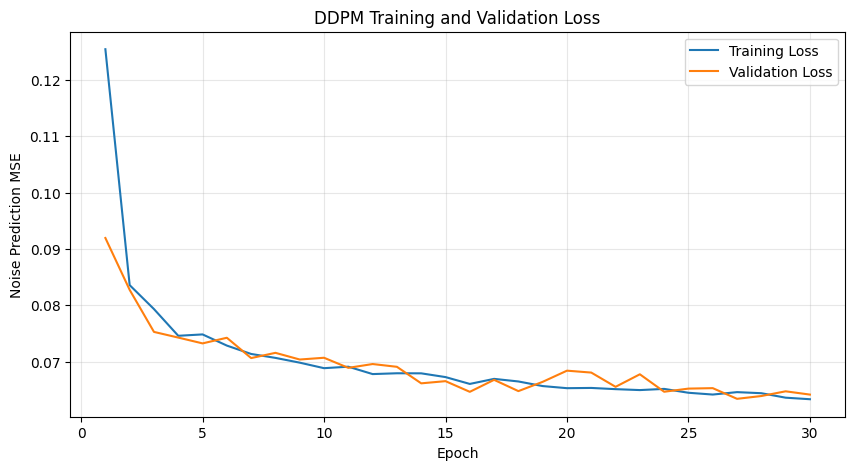

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss",
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss",
)

plt.xlabel("Epoch")
plt.ylabel("Noise Prediction MSE")
plt.title("DDPM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    FIGURES_DIR / "ddpm_training_curves.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


In [12]:
checkpoint = torch.load(
    CHECKPOINT_DIR / "ddpm_best.pth",
    map_location=DEVICE,
    weights_only=True,
)

noise_predictor.load_state_dict(checkpoint["model_state_dict"])
noise_predictor.eval()

print(f"Best checkpoint epoch: {checkpoint['epoch']}")
print(f"Best validation loss: {checkpoint['val_loss']:.6f}")


Best checkpoint epoch: 27
Best validation loss: 0.063390


In [13]:
@torch.no_grad()
def reverse_diffusion(model, num_samples=16, save_trajectory=False):
    model.eval()

    images = torch.randn(
        num_samples,
        1,
        28,
        28,
        device=DEVICE,
    )

    trajectory = []

    selected_steps = {499, 400, 300, 200, 100, 50, 10, 0}

    for t in reversed(range(TIMESTEPS)):
        timesteps = torch.full(
            (num_samples,),
            t,
            device=DEVICE,
            dtype=torch.long,
        )

        predicted_noise = predict_noise(images, timesteps, model, TIMESTEPS)

        alpha_t = alphas[t]
        alpha_bar_t = alpha_bars[t]
        beta_t = betas[t]

        images = (1.0 / torch.sqrt(alpha_t)) * (
            images - (beta_t / torch.sqrt(1.0 - alpha_bar_t)) * predicted_noise
        )

        if t > 0:
            noise = torch.randn_like(images)
            images += torch.sqrt(beta_t) * noise

        if save_trajectory and t in selected_steps:
            trajectory.append((t, images.detach().clone()))

    images = images.clamp(-1.0, 1.0)

    if save_trajectory:
        return images, trajectory

    return images


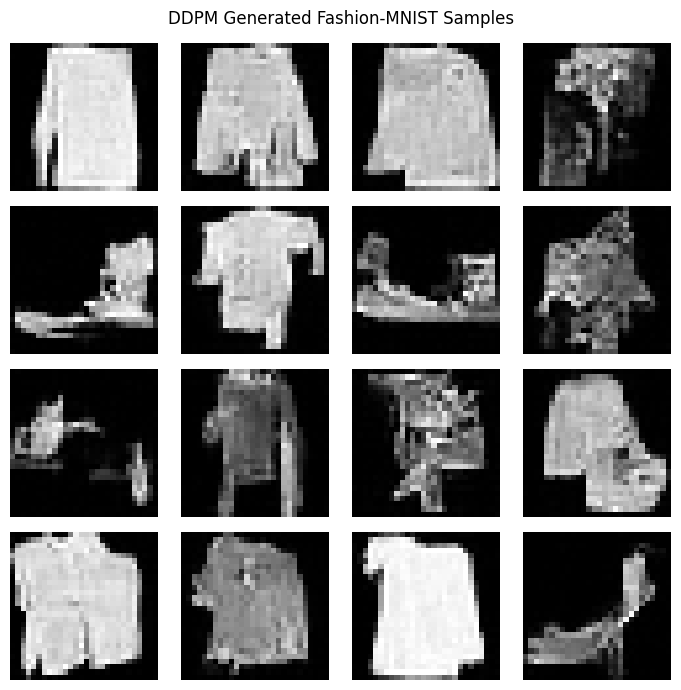

In [14]:
generated_images = reverse_diffusion(
    noise_predictor,
    num_samples=16,
)

generated_images = (generated_images + 1.0) / 2.0

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for index, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[index, 0].cpu(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.axis("off")

plt.suptitle("DDPM Generated Fashion-MNIST Samples")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "ddpm_random_samples.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


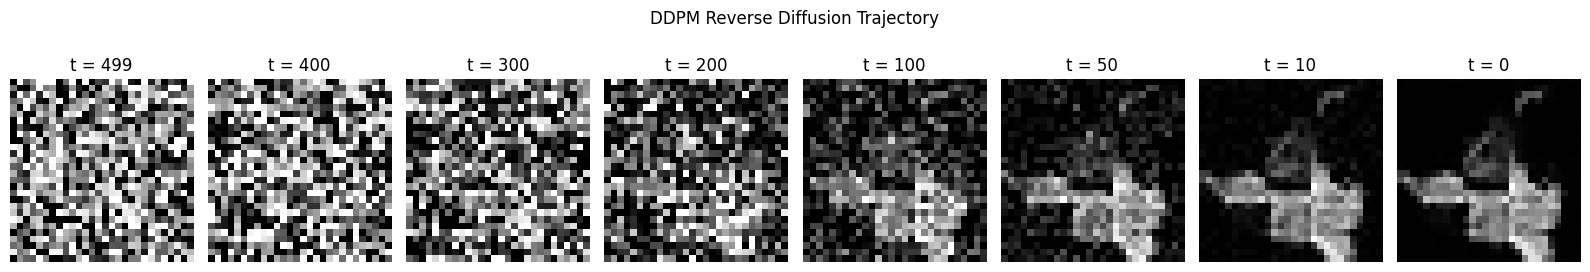

In [15]:
generated_images, trajectory = reverse_diffusion(
    noise_predictor,
    num_samples=1,
    save_trajectory=True,
)

fig, axes = plt.subplots(1, len(trajectory), figsize=(16, 3))

for ax, (timestep, image) in zip(axes, trajectory):
    display_image = (image[0, 0].cpu() + 1.0) / 2.0

    ax.imshow(
        display_image,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"t = {timestep}")
    ax.axis("off")

plt.suptitle("DDPM Reverse Diffusion Trajectory")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "ddpm_reverse_trajectory.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


In [16]:
def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "xpu":
        torch.xpu.synchronize()


average_epoch_time = total_training_time / EPOCHS

# Warm-up
_ = reverse_diffusion(
    noise_predictor,
    num_samples=64,
)

synchronize_device()

# Measure inference latency
inference_start = time.time()

_ = reverse_diffusion(
    noise_predictor,
    num_samples=64,
)

synchronize_device()

inference_time = time.time() - inference_start
inference_latency_ms = (inference_time / 64) * 1000

print(f"Total training time: {total_training_time:.2f}s")
print(f"Average epoch time: {average_epoch_time:.2f}s")
print(f"Inference latency: {inference_latency_ms:.2f} ms/image")
print(f"Batch inference time: {inference_time:.2f}s")


Total training time: 1417.44s
Average epoch time: 47.25s
Inference latency: 85.27 ms/image
Batch inference time: 5.46s


In [17]:
ddpm_metrics = {
    "model": "DDPM",
    "architecture": "CNN Noise Predictor",
    "image_shape": [1, 28, 28],
    "timesteps": TIMESTEPS,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "training_time_seconds": total_training_time,
    "average_epoch_time_seconds": average_epoch_time,
    "inference_latency_ms_per_image_batch64": inference_latency_ms,
    "best_validation_loss": best_val_loss,
    "final_train_loss": train_losses[-1],
    "final_val_loss": val_losses[-1],
    "fid_score": None,
    "checkpoint": "ddpm_best.pth",
}

with open(METRICS_DIR / "ddpm.json", "w") as file:
    json.dump(ddpm_metrics, file, indent=4)

print(json.dumps(ddpm_metrics, indent=4))


{
    "model": "DDPM",
    "architecture": "CNN Noise Predictor",
    "image_shape": [
        1,
        28,
        28
    ],
    "timesteps": 500,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "training_time_seconds": 1417.4372045993805,
    "average_epoch_time_seconds": 47.24790681997935,
    "inference_latency_ms_per_image_batch64": 85.26585251092911,
    "best_validation_loss": 0.06339031197343553,
    "final_train_loss": 0.06331867804271835,
    "final_val_loss": 0.06414113035372325,
    "fid_score": null,
    "checkpoint": "ddpm_best.pth"
}
